In [1]:
!pip install pgmpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 51.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 756.0/756.0 kB 30.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 53.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 28.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 44.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 5.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 16.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 7.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 6.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 41.2 MB/s eta 0:00:00
  Attempting uninstall: nvidia-nvjitlink-cu12

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score

from umap import UMAP
from shapely import wkt
import folium
import hdbscan

from pgmpy.inference import VariableElimination
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.estimators import BayesianEstimator
from pgmpy.estimators import HillClimbSearch, BDs

from mlxtend.frequent_patterns import apriori, association_rules
from mlxtend.preprocessing import TransactionEncoder

import geopandas as gpd

/usr/local/lib/python3.11/dist-packages/geopandas/_compat.py:7: DeprecationWarning: The 'shapely.geos' module is deprecated, and will be removed in a future version. All attributes of 'shapely.geos' are available directly from the top-level 'shapely' namespace (since shapely 2.0.0).
  import shapely.geos


###Cuales son las principales causas de los siniestros de transito en Chile y como se concentran en los puntos criticos de la RM?

Carga de datos

In [2]:
df = pd.read_csv("/content/accidentes.csv")

# Convertir geometry a objeto shapely
df["geometry"] = df["geometry"].apply(wkt.loads)
gdf = gpd.GeoDataFrame(df, geometry="geometry", crs="EPSG:32719")  # Ajustar CRS si corresponde

# Convertir a lat/lon para visualización
gdf = gdf.to_crs(epsg=4326)
gdf["lat"] = gdf.geometry.y
gdf["lon"] = gdf.geometry.x

Normalizamos y preprocesamos

In [3]:
# Seleccionar columnas
def get_columns(prefix):
    return [col for col in df.columns if col.startswith(prefix)]

cols_causa = get_columns("Causa__")
cols_tipo = get_columns("Tipo__")
cols_clima = get_columns("EstadoAtm__")
cols_cond = get_columns("Condicion__")

# Construir matriz de features
X = gdf[["lat", "lon"] + cols_causa + cols_tipo + cols_clima + cols_cond].copy()

# Normalización
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

#### HDBSCAN

In [4]:
clusterer = hdbscan.HDBSCAN(min_cluster_size=30, min_samples=10)
gdf["cluster_hdbscan"] = clusterer.fit_predict(X_scaled)
print("Resultados HDBSCAN:")
print(gdf["cluster_hdbscan"].value_counts())

/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


Resultados HDBSCAN:
cluster_hdbscan
-1     4295
 36    2126
 32    1616
 22     573
 20     375
       ... 
 2       32
 87      31
 73      31
 60      30
 58      30
Name: count, Length: 100, dtype: int64


#### DBSCAN comenzamos con eps 0.5 pero lo reduci un poco para que el cluster 0 no sea tan grande, probemos con 0.3 y me dio un resultado similar, con 0.1 quedo muchos datos en el noise, osea no quedaron agrupado, que tampoco es ideal.

In [10]:
dbscan = DBSCAN(eps=0.3, min_samples=10)
gdf["cluster_dbscan"] = dbscan.fit_predict(X_scaled)
print("Resultados DBSCAN:")
print(gdf["cluster_dbscan"].value_counts())

Resultados DBSCAN:
cluster_dbscan
-1     7321
 0     6615
 22     305
 1      281
 17     229
       ... 
 87       8
 65       8
 75       6
 67       6
 86       6
Name: count, Length: 90, dtype: int64


#### Por esto mismo compararemos: eps vs Numero de clusters, eps vs porcentaje de noise, eps vs silhoutte score

100%|██████████| 11/11 [00:49<00:00,  4.48s/it]


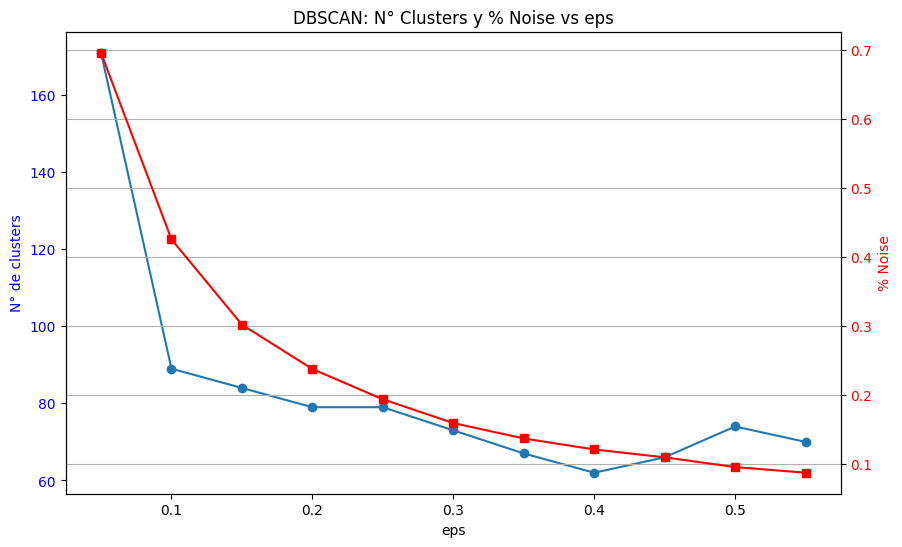

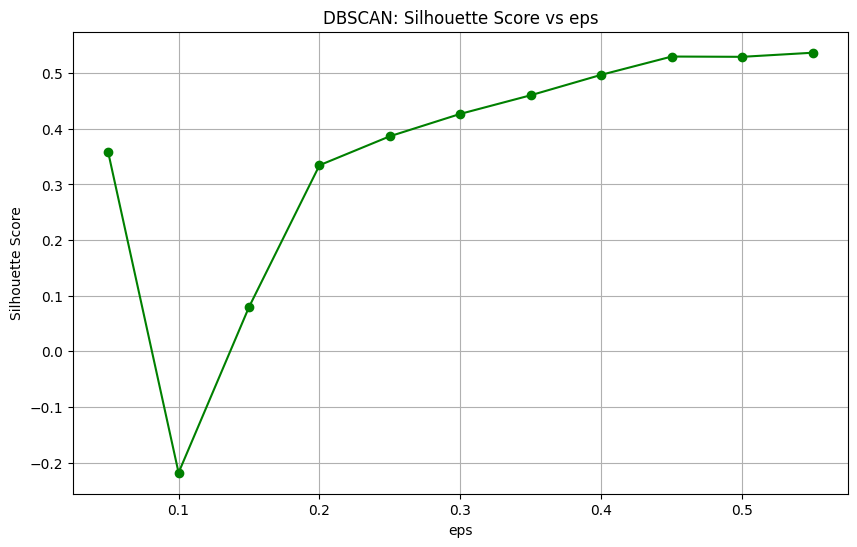

In [11]:
from tqdm import tqdm

# Rangos de eps a probar
eps_values = np.arange(0.05, 0.6, 0.05)

# Listas para guardar resultados
n_clusters_list = []
noise_ratio_list = []
silhouette_list = []

for eps in tqdm(eps_values):
    dbscan = DBSCAN(eps=eps, min_samples=10)
    gdf["cluster_dbscan"] = dbscan.fit_predict(X_scaled)

    # Noise
    noise_ratio = (gdf["cluster_dbscan"] == -1).sum() / len(gdf)

    # N° clusters (excluyendo noise)
    n_clusters = len(gdf["cluster_dbscan"].unique()) - (1 if -1 in gdf["cluster_dbscan"].unique() else 0)

    # Silhouette
    mask_db = gdf["cluster_dbscan"] != -1
    if mask_db.sum() > 1 and n_clusters > 1:
        sil_score = silhouette_score(X_scaled[mask_db], gdf.loc[mask_db, "cluster_dbscan"])
    else:
        sil_score = np.nan

    # Guardar
    noise_ratio_list.append(noise_ratio)
    n_clusters_list.append(n_clusters)
    silhouette_list.append(sil_score)

# Graficar
fig, ax1 = plt.subplots(figsize=(10,6))

ax1.plot(eps_values, n_clusters_list, label="N° Clusters", marker='o')
ax1.set_xlabel("eps")
ax1.set_ylabel("N° de clusters", color='b')
ax1.tick_params(axis='y', labelcolor='b')

ax2 = ax1.twinx()
ax2.plot(eps_values, noise_ratio_list, label="% Noise", color='r', marker='s')
ax2.set_ylabel("% Noise", color='r')
ax2.tick_params(axis='y', labelcolor='r')

plt.title("DBSCAN: N° Clusters y % Noise vs eps")
plt.grid()
plt.show()

# Silhouette plot
plt.figure(figsize=(10,6))
plt.plot(eps_values, silhouette_list, label="Silhouette Score", marker='o', color='g')
plt.xlabel("eps")
plt.ylabel("Silhouette Score")
plt.title("DBSCAN: Silhouette Score vs eps")
plt.grid()
plt.show()


Con esto podemos concluir que para DBSCAN: si uno quiere clusters mas finos eligiria eps 0.3 a 0.35 ya que aca hay un buen silhoutte score, noise razonable y un numero de clusters razonables, pero en 0.4 o 0.5 tenemos una calidad alta por un muy buen silhoutte score y tenemos clusters mas compactos, y bajo noise, asi que nos quedamos con 0.5

In [12]:
dbscan = DBSCAN(eps=0.5, min_samples=10)
gdf["cluster_dbscan"] = dbscan.fit_predict(X_scaled)
print("Resultados DBSCAN:")
print(gdf["cluster_dbscan"].value_counts())

Resultados DBSCAN:
cluster_dbscan
 0     7273
 2     2168
-1     1646
 4     1615
 10     563
       ... 
 64      10
 66      10
 45       8
 67       8
 69       4
Name: count, Length: 75, dtype: int64


#### Comparacion silhoutte score

In [13]:
# HDBSCAN
mask_hdb = gdf["cluster_hdbscan"] != -1
if mask_hdb.sum() > 1:
    sil_hdbscan = silhouette_score(X_scaled[mask_hdb], gdf.loc[mask_hdb, "cluster_hdbscan"])
else:
    sil_hdbscan = np.nan

# DBSCAN
mask_db = gdf["cluster_dbscan"] != -1
if mask_db.sum() > 1:
    sil_dbscan = silhouette_score(X_scaled[mask_db], gdf.loc[mask_db, "cluster_dbscan"])
else:
    sil_dbscan = np.nan

print(f"Silhouette HDBSCAN: {sil_hdbscan:.4f}")
print(f"Silhouette DBSCAN: {sil_dbscan:.4f}")

Silhouette HDBSCAN: 0.5254
Silhouette DBSCAN: 0.5294


Por lo tanto, podemos concluir que ambos metodos (HDBSCAN, DBSCAN) son utiles para esta problematica del proyecto, ya que tienen scores similares cercanos a 0.5 por lo que denota una buena calidad de clusters en nuestro dataset de accidentes.

## PROBLEMATICA 1

mapa HDBSCAN

In [14]:
### 🚦 Paso 6: Visualización en Folium
# Colores por cluster
import random
random.seed(42)

def make_color_dict(values):
    return {clu: f"#{random.randint(0, 0xFFFFFF):06x}" for clu in values}

# Mapa HDBSCAN
colors_hdb = make_color_dict(gdf["cluster_hdbscan"].unique())
m_hdb = folium.Map(location=[-33.45, -70.65], zoom_start=11)
for _, row in gdf.iterrows():
    folium.CircleMarker(
        location=[row["lat"], row["lon"]],
        radius=3,
        color=colors_hdb[row["cluster_hdbscan"]],
        fill=True,
        fill_opacity=0.7,
        popup=f"Cluster HDBSCAN: {row['cluster_hdbscan']}"
    ).add_to(m_hdb)

# Mapa DBSCAN
colors_db = make_color_dict(gdf["cluster_dbscan"].unique())
m_db = folium.Map(location=[-33.45, -70.65], zoom_start=11)
for _, row in gdf.iterrows():
    folium.CircleMarker(
        location=[row["lat"], row["lon"]],
        radius=3,
        color=colors_db[row["cluster_dbscan"]],
        fill=True,
        fill_opacity=0.7,
        popup=f"Cluster DBSCAN: {row['cluster_dbscan']}"
    ).add_to(m_db)


display(m_hdb)




Output hidden; open in https://colab.research.google.com to view.

#### MOSTRANDO SOLO LOS 10 CLUSTERS MAS GRANDES (HDBSCAN)

In [16]:
# 🚦 Mostrar sólo los top 10 clusters HDBSCAN
top_clusters = gdf["cluster_hdbscan"].value_counts().iloc[1:11].index.tolist()  # Excluye -1

colors_top = make_color_dict(top_clusters)

m_top_hdb = folium.Map(location=[-33.45, -70.65], zoom_start=11)

for _, row in gdf[gdf["cluster_hdbscan"].isin(top_clusters)].iterrows():
    folium.CircleMarker(
        location=[row["lat"], row["lon"]],
        radius=4,
        color=colors_top[row["cluster_hdbscan"]],
        fill=True,
        fill_opacity=0.7,
        popup=f"Cluster: {row['cluster_hdbscan']}"
    ).add_to(m_top_hdb)

m_top_hdb


Output hidden; open in https://colab.research.google.com to view.

### MAPA QUE MUESTRA SOLO LOS PUNTOS AGRUPADOS (EVITANDO CLUSTER =-1) (HDSCAN)

In [17]:
# 🚦 Mostrar sólo los puntos agrupados (sin noise)
mask_cluster = gdf["cluster_hdbscan"] != -1

colors_hdb_clean = make_color_dict(gdf.loc[mask_cluster, "cluster_hdbscan"].unique())

m_clean_hdb = folium.Map(location=[-33.45, -70.65], zoom_start=11)

for _, row in gdf[mask_cluster].iterrows():
    folium.CircleMarker(
        location=[row["lat"], row["lon"]],
        radius=3,
        color=colors_hdb_clean[row["cluster_hdbscan"]],
        fill=True,
        fill_opacity=0.7,
        popup=f"Cluster: {row['cluster_hdbscan']}"
    ).add_to(m_clean_hdb)

m_clean_hdb


Output hidden; open in https://colab.research.google.com to view.

#### mapa DBSCAN

In [15]:
display(m_db)

Output hidden; open in https://colab.research.google.com to view.

#### Resumen de causas por cluster de HDBSCAN (RESPUESTA A NUESTRA PRIMERA PROBLEMATICA)

In [18]:
resumen_causas_hdb = gdf.groupby("cluster_hdbscan")[cols_causa].mean().T
print("\nResumen de causas por cluster (HDBSCAN):")
print(resumen_causas_hdb)


Resumen de causas por cluster (HDBSCAN):
cluster_hdbscan                             -1         0    1        2   \
Causa__ALCOHOL EN CONDUCTOR            0.009080  0.048780  0.0  0.09375   
Causa__ALCOHOL EN PASAJERO             0.000233  0.000000  0.0  0.00000   
Causa__ALCOHOL EN PEATON               0.005355  0.000000  0.0  0.00000   
Causa__CAUSAS NO DETERMINADAS          0.047730  0.073171  0.0  0.03125   
Causa__DEFICIENCIAS VIALES             0.006286  0.000000  0.0  0.00000   
Causa__DESOBEDIENCIA A SEÑALIZACION    0.008382  0.097561  0.0  0.06250   
Causa__DROGAS Y/O FATIGA EN CONDUCTOR  0.003027  0.000000  0.0  0.00000   
Causa__FALLAS MECANICAS                0.005588  0.024390  0.0  0.00000   
Causa__IMPRUDENCIA DEL CONDUCTOR       0.855413  0.609756  0.0  0.75000   
Causa__IMPRUDENCIA DEL PASAJERO        0.000000  0.000000  1.0  0.00000   
Causa__IMPRUDENCIA DEL PEATON          0.003027  0.000000  0.0  0.00000   
Causa__OTRAS CAUSAS                    0.030035  0.097561 

### Top 5 clusters por cada causa

In [19]:
top_causas = {}

for causa in cols_causa:
    top5 = resumen_causas_hdb.loc[causa].sort_values(ascending=False).head(5)
    top_causas[causa] = top5

# Mostrar resultados
for causa, series in top_causas.items():
    print(f"\nTop 5 clusters para: {causa}")
    print(series)



Top 5 clusters para: Causa__ALCOHOL EN CONDUCTOR
cluster_hdbscan
19    1.0
20    1.0
17    1.0
16    1.0
37    1.0
Name: Causa__ALCOHOL EN CONDUCTOR, dtype: float64

Top 5 clusters para: Causa__ALCOHOL EN PASAJERO
cluster_hdbscan
-1    0.000233
 0    0.000000
 1    0.000000
 2    0.000000
 3    0.000000
Name: Causa__ALCOHOL EN PASAJERO, dtype: float64

Top 5 clusters para: Causa__ALCOHOL EN PEATON
cluster_hdbscan
-1    0.005355
 0    0.000000
 1    0.000000
 2    0.000000
 3    0.000000
Name: Causa__ALCOHOL EN PEATON, dtype: float64

Top 5 clusters para: Causa__CAUSAS NO DETERMINADAS
cluster_hdbscan
12    1.0
40    1.0
39    1.0
38    1.0
45    1.0
Name: Causa__CAUSAS NO DETERMINADAS, dtype: float64

Top 5 clusters para: Causa__DEFICIENCIAS VIALES
cluster_hdbscan
-1    0.006286
 0    0.000000
 1    0.000000
 2    0.000000
 3    0.000000
Name: Causa__DEFICIENCIAS VIALES, dtype: float64

Top 5 clusters para: Causa__DESOBEDIENCIA A SEÑALIZACION
cluster_hdbscan
21    1.0
32    1.0
31    1

### Mapa con causa dominante por cluster:

In [20]:
# 🚦 Mapa con popup: causa dominante por cluster

# Calcular causa dominante por cluster
causa_dom = resumen_causas_hdb.idxmax()

# Filtrar sólo puntos agrupados
mask_cluster = gdf["cluster_hdbscan"] != -1

# Asignar causa dominante a cada punto
gdf["causa_dom"] = gdf["cluster_hdbscan"].map(causa_dom)

# Colores
colors_hdb_dom = make_color_dict(gdf.loc[mask_cluster, "cluster_hdbscan"].unique())

# Mapa
m_dom_hdb = folium.Map(location=[-33.45, -70.65], zoom_start=11)

for _, row in gdf[mask_cluster].iterrows():
    folium.CircleMarker(
        location=[row["lat"], row["lon"]],
        radius=3,
        color=colors_hdb_dom[row["cluster_hdbscan"]],
        fill=True,
        fill_opacity=0.7,
        popup=f"Cluster: {row['cluster_hdbscan']}<br>Causa dominante: {row['causa_dom'].replace('Causa__', '').title()}"
    ).add_to(m_dom_hdb)

m_dom_hdb


Output hidden; open in https://colab.research.google.com to view.

### Mapa con color por causa dominante

In [23]:
# 🚦 Mapa con color por causa dominante (no por cluster)

# Calcular causa dominante por cluster
causa_dom = resumen_causas_hdb.idxmax()

# Y la proporción máxima (para el popup)
causa_dom_val = resumen_causas_hdb.max()

# Filtrar sólo puntos agrupados
mask_cluster = gdf["cluster_hdbscan"] != -1

# Asignar causa dominante y % a cada punto
gdf["causa_dom"] = gdf["cluster_hdbscan"].map(causa_dom)
gdf["causa_dom_val"] = gdf["cluster_hdbscan"].map(causa_dom_val)

# Crear lista de causas únicas para colores
causas_unicas = gdf.loc[mask_cluster, "causa_dom"].unique()

# Colores por causa
colors_causa = make_color_dict(causas_unicas)

# Mapa
m_causa = folium.Map(location=[-33.45, -70.65], zoom_start=11)

for _, row in gdf[mask_cluster].iterrows():
    folium.CircleMarker(
        location=[row["lat"], row["lon"]],
        radius=4,
        color=colors_causa[row["causa_dom"]],
        fill=True,
        fill_opacity=0.8,
        popup=f"Cluster: {row['cluster_hdbscan']}<br>Causa dominante: {row['causa_dom'].replace('Causa__','').title()}<br>Proporción: {row['causa_dom_val']:.2%}"
    ).add_to(m_causa)

m_causa


Output hidden; open in https://colab.research.google.com to view.

Podemos concluir con este mapa anterior y todo el analisis completo anterior que la causa mas dominante es la imprudencia del conductor, Tenemos tambien que como causas mayores las no determinadas y 'otras causas', seguido por el alcohol en clusters especificos, y desobencencia a la señalizacion.


### ISOLATION FOREST (DETECCION DE OUTLIERS)

In [24]:
from sklearn.ensemble import IsolationForest

# Features que ya tenías
X = gdf[["lat", "lon"] + cols_causa + cols_tipo + cols_clima + cols_cond].copy()

# Normalizar
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


In [25]:
# Ajustar Isolation Forest
iso_forest = IsolationForest(n_estimators=200, contamination=0.05, random_state=42)  # 5% de outliers esperados

# Fit y predicción
gdf["iso_outlier"] = iso_forest.fit_predict(X_scaled)

# iso_outlier = -1 → outlier
# iso_outlier = 1 → normal


In [26]:
print(gdf["iso_outlier"].value_counts())

# Porcentaje de outliers detectados
pct_outliers = (gdf["iso_outlier"] == -1).mean() * 100
print(f"Outliers detectados: {pct_outliers:.2f}%")


iso_outlier
 1    16338
-1      860
Name: count, dtype: int64
Outliers detectados: 5.00%


In [27]:
# Mapa: outliers vs normales
m_outliers = folium.Map(location=[-33.45, -70.65], zoom_start=11)

for _, row in gdf.iterrows():
    color = "red" if row["iso_outlier"] == -1 else "blue"
    folium.CircleMarker(
        location=[row["lat"], row["lon"]],
        radius=4 if row["iso_outlier"] == -1 else 2,
        color=color,
        fill=True,
        fill_opacity=0.8,
        popup=f"Outlier: {'Yes' if row['iso_outlier'] == -1 else 'No'}<br>Cluster: {row['cluster_hdbscan']}"
    ).add_to(m_outliers)

m_outliers


Output hidden; open in https://colab.research.google.com to view.